# Telco customer churn

**Edwige Mpore Rwagasana · Individual BUAI 435 coursework**

**Question:** How well do selected customer characteristics distinguish churners from customers who stay?

**Data and scope:** Course-supplied `Telco-Customer-Churn.csv`; 7,032 customers after missing-value removal. The upstream release is not documented.

**Approach:** Exploratory analysis and a nine-predictor binomial GLM with logit link; training-only scaling and a stratified 80/20 split.

**Main finding:** Saved test ROC AUC is 0.831; churn recall is 0.55 at threshold 0.50 across 1,407 test customers.

**Main limitation:** This is one held-out split, with an assignment-specified threshold. Associations do not establish intervention effects.

[Project guide](README.md) · [Authorship](../../README.md#authorship-and-ai-assistance) · [Verification](../../VERIFICATION.md)

The outputs below are historical notebook results. Subsequent IPython execution reproduced selected summaries; details are in the verification record.

## 1. Data preparation

Convert `TotalCharges` to numeric and drop rows with missing values; encode churn as 0/1. Construct six indicator variables, omitting one reference category per predictor. The original loader output was cleared during sharing to avoid distributing source-row previews; the saved downstream tenure summary contains 7,032 observations.

In [ ]:
# Data files are supplied separately. See README.md.
from IPython.display import display


In [7]:
# Import np and pd
import numpy as np
import pandas as pd

In [ ]:
# Load the dataset
file_path = 'data/Telco-Customer-Churn.csv'
df = pd.read_csv(file_path)

# Convert TotalCharges to numeric. Any blank or invalid values become NaN.
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

# Inspect the rows with missing TotalCharges before dropping them.
missing_total_charges = df[df['TotalCharges'].isna()]
print('Rows with missing TotalCharges:')
display(missing_total_charges)
print('Tenure values in these rows:', missing_total_charges['tenure'].unique())

# These customers have tenure = 0, so they are new customers who have not
# accumulated total charges. There are only a few, so they are dropped.
df = df.dropna(subset=['TotalCharges']).copy()

# Convert the target variable to 1 for Yes and 0 for No.
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})

# Manually create the six required dummy variables.
df['gender_Female'] = (df['gender'] == 'Female').astype(int)
df['PhoneService_Yes'] = (df['PhoneService'] == 'Yes').astype(int)
df['InternetService_Fiber optic'] = (df['InternetService'] == 'Fiber optic').astype(int)
df['InternetService_No'] = (df['InternetService'] == 'No').astype(int)
df['Contract_One year'] = (df['Contract'] == 'One year').astype(int)
df['Contract_Two year'] = (df['Contract'] == 'Two year').astype(int)

# Sanity checks
df.info()
display(df.head())

## 2. Exploratory analysis

Inspect tenure and churn by contract type. These comparisons describe associations rather than causal effects.

Basic statistics for tenure:


count    7032.000000
mean       32.421786
std        24.545260
min         1.000000
25%         9.000000
50%        29.000000
75%        55.000000
max        72.000000
Name: tenure, dtype: float64

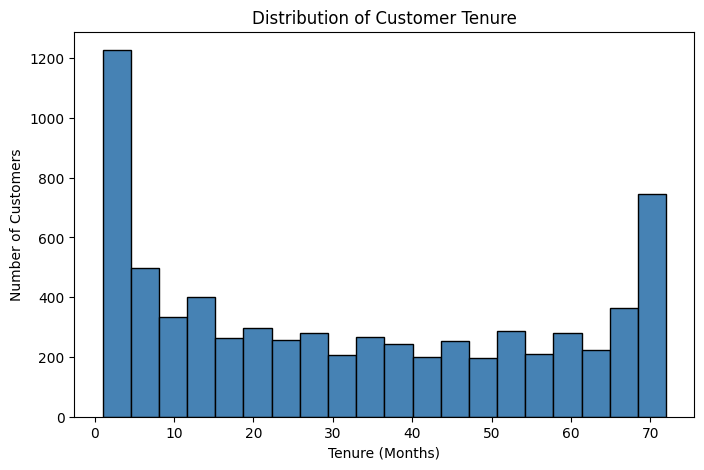

Overall churn rate: 26.58%
Churn rate by contract type:


                  Stayed   Churned
Contract                          
Month-to-month  0.572903  0.427097
One year        0.887228  0.112772
Two year        0.971513  0.028487

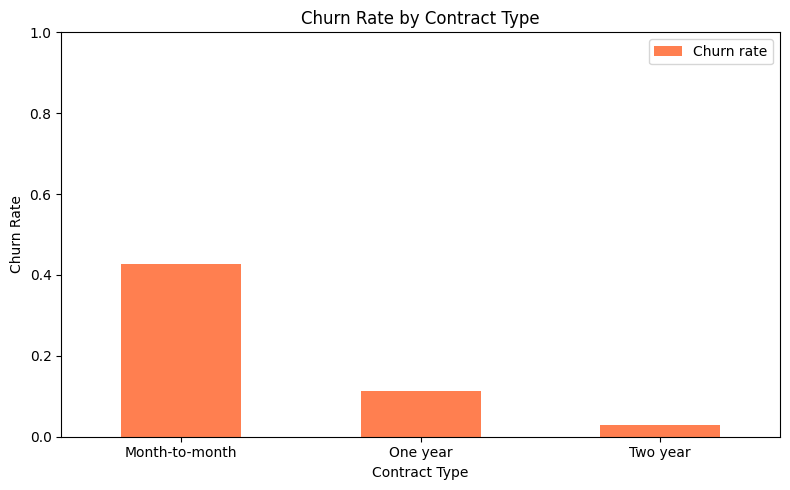

In [11]:
import matplotlib.pyplot as plt

# Basic statistics and distribution of tenure
print('Basic statistics for tenure:')
display(df['tenure'].describe())

plt.figure(figsize=(8, 5))
plt.hist(df['tenure'], bins=20, edgecolor='black', color='steelblue')
plt.title('Distribution of Customer Tenure')
plt.xlabel('Tenure (Months)')
plt.ylabel('Number of Customers')
plt.show()

# Overall churn rate
overall_churn_rate = df['Churn'].mean()
print(f'Overall churn rate: {overall_churn_rate:.2%}')

# Churn rate by contract type
churn_by_contract = pd.crosstab(df['Contract'], df['Churn'], normalize='index')
churn_by_contract.columns = ['Stayed', 'Churned']
print('Churn rate by contract type:')
display(churn_by_contract)

ax = churn_by_contract['Churned'].plot(
    kind='bar', figsize=(8, 5), color='coral', label='Churn rate'
)
ax.set_title('Churn Rate by Contract Type')
ax.set_xlabel('Contract Type')
ax.set_ylabel('Churn Rate')
ax.set_ylim(0, 1)
ax.legend()
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### EDA observations

- The tenure distribution shows that the dataset includes many newer customers as well as a large group of long-term customers.
- Churn is more strongly associated with month-to-month contracts than with one-year or two-year contracts.
- The lower churn rates among customers with longer contracts suggest an association between contract commitment and customer retention, but this does not prove that the contract itself causes customers to stay.

## 3. Model specification and estimation

Use nine predictors and an intercept in a binomial GLM with logit link. Fit scaling on the training continuous variables only. Keep indicators at 0/1. The stratified split uses seed 42, with 5,625 training and 1,407 test observations.

### Pre-specified model features

The continuous predictors are `tenure`, `MonthlyCharges`, and `TotalCharges`. The six dummy predictors are `gender_Female`, `PhoneService_Yes`, `InternetService_Fiber optic`, `InternetService_No`, `Contract_One year`, and `Contract_Two year`. The omitted reference categories are Male for gender, No for PhoneService, DSL for InternetService, and Month-to-month for Contract. These nine features were selected before evaluating the test set.

In [13]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import statsmodels.api as sm

continuous_features = ['tenure', 'MonthlyCharges', 'TotalCharges']
dummy_features = [
    'gender_Female',
    'PhoneService_Yes',
    'InternetService_Fiber optic',
    'InternetService_No',
    'Contract_One year',
    'Contract_Two year'
]
selected_features = continuous_features + dummy_features

X = df[selected_features].copy()
y = df['Churn'].copy()

# Split once so the test set remains a final, unseen evaluation set.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Fit the scaler only on the training values of the continuous predictors.
scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()
X_train_scaled[continuous_features] = scaler.fit_transform(X_train[continuous_features])
X_test_scaled[continuous_features] = scaler.transform(X_test[continuous_features])

# The dummy variables remain unchanged at 0/1.
print('Unique training values for each dummy variable:')
for column in dummy_features:
    print(column, sorted(X_train_scaled[column].unique()))

# Add the intercept and fit the binomial GLM.
X_train_model = sm.add_constant(X_train_scaled, has_constant='add').astype(float)
X_test_model = sm.add_constant(X_test_scaled, has_constant='add').astype(float)

churn_model = sm.GLM(
    y_train.astype(float), X_train_model, family=sm.families.Binomial()
).fit()

print(churn_model.summary())

Unique training values for each dummy variable:
gender_Female [np.int64(0), np.int64(1)]
PhoneService_Yes [np.int64(0), np.int64(1)]
InternetService_Fiber optic [np.int64(0), np.int64(1)]
InternetService_No [np.int64(0), np.int64(1)]
Contract_One year [np.int64(0), np.int64(1)]
Contract_Two year [np.int64(0), np.int64(1)]
                 Generalized Linear Model Regression Results                  
Dep. Variable:                  Churn   No. Observations:                 5625
Model:                            GLM   Df Residuals:                     5615
Model Family:                Binomial   Df Model:                            9
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -2394.1
Date:                Tue, 22 Sep 2026   Deviance:                       4788.2
Time:                        17:56:00   Pearson chi2:                 6.86e+03
No. Iterations:                     7   Pseu

### Interpreting the saved GLM estimates

These are adjusted associations with churn **log odds**, holding the other included predictors fixed. The intervals are the saved model's nonrobust 95% confidence intervals. For continuous variables, a one-unit change means **one training-set standard deviation**, not one month or one currency unit.

| Predictor / comparison | Coefficient | Saved 95% CI | Interpretation |
|---|---:|---:|---|
| Tenure, +1 training SD | −1.4175 | [−1.745, −1.090] | Longer tenure is associated with lower churn log odds. |
| Monthly charges, +1 training SD | 0.2323 | [−0.027, 0.491] | The estimate is positive, but the interval includes zero. |
| Fiber-optic internet vs DSL | 0.9965 | [0.710, 1.283] | Fiber-optic service is associated with higher churn log odds than DSL. |
| One-year vs month-to-month contract | −0.9958 | [−1.228, −0.764] | One-year contracts are associated with lower churn log odds. |
| Two-year vs month-to-month contract | −1.8568 | [−2.229, −1.485] | Two-year contracts are associated with lower churn log odds. |

These coefficients are not probability changes or relative risks. They describe conditional associations in this specification; they do not show that changing a contract or service would cause churn to change.

## 4. Held-out evaluation

Evaluate test probabilities at the assignment-specified threshold of 0.50. The saved report, confusion matrix, and ROC curve describe discrimination and classification on this single split.

Classification Report:
              precision    recall  f1-score   support

      Stayed       0.84      0.88      0.86      1033
     Churned       0.61      0.55      0.58       374

    accuracy                           0.79      1407
   macro avg       0.73      0.71      0.72      1407
weighted avg       0.78      0.79      0.78      1407

Confusion Matrix:
[[904 129]
 [169 205]]


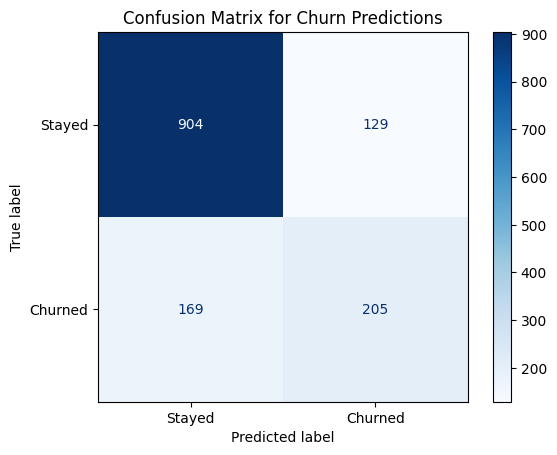

Test AUC: 0.831


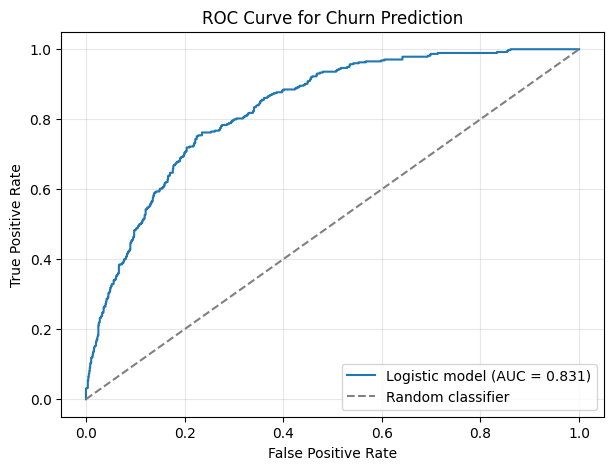

In [15]:
from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    roc_auc_score, roc_curve
)

# Predict churn probabilities and use the required 0.50 threshold.
y_test_probability = churn_model.predict(X_test_model)
y_test_prediction = (y_test_probability >= 0.50).astype(int)

print('Classification Report:')
print(classification_report(y_test, y_test_prediction, target_names=['Stayed', 'Churned']))

cm = confusion_matrix(y_test, y_test_prediction)
print('Confusion Matrix:')
print(cm)

ConfusionMatrixDisplay(
    confusion_matrix=cm, display_labels=['Stayed', 'Churned']
).plot(cmap='Blues')
plt.title('Confusion Matrix for Churn Predictions')
plt.show()

auc_score = roc_auc_score(y_test, y_test_probability)
print(f'Test AUC: {auc_score:.3f}')

false_positive_rate, true_positive_rate, thresholds = roc_curve(
    y_test, y_test_probability
)
plt.figure(figsize=(7, 5))
plt.plot(
    false_positive_rate, true_positive_rate,
    label=f'Logistic model (AUC = {auc_score:.3f})'
)
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Random classifier')
plt.title('ROC Curve for Churn Prediction')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Classification trade-off

At threshold 0.50, the model detects 205 of 374 churners and misses 169. It flags 129 customers who stay. Churn recall is 205/374 (about 0.55); precision is 205/334 (about 0.61). These errors illustrate missed opportunities and unnecessary outreach, but no intervention costs, retention benefits, or revenue were measured.

## 5. Limitations and future work

Coefficients describe adjusted associations, not causal effects. Continuous coefficients refer to one training-set standard deviation. One random split does not establish temporal or external stability; the chosen threshold was not validated against costs.

Future work, not completed, includes assessing calibration and stability on suitable additional data. Later threshold selection should use separate validation data. No deployment or intervention outcomes are claimed.